In [1]:
import pandas as pd
import numpy as np
import utils

In [2]:
df = pd.read_csv("Data Collection Form_Cervix Cancer - V1_De_identified.csv")
df.head()

,Study Code,Age,Stage of Malignancy,ECOG Performance Status,Suburb of Residence,SEIFA Score,SEIFA Quartile,SEIFA Statewide Thirtiles,Postcode,Valid,...,Stage (1-IV),Time 1 - Compliance,Time 2 - Compliant,Time 3 - Compliant,In Area/Out of Area Time 1 Categories,In Area/Out of Area Time 2 Categories,In Area/Out of Area Time 3 Categories,IRSD (Time Frame 1),IRSD (Time Frame 2),IRSD (Time Frame 3)
0,1,65,IIIC1,0.0,Merrylands,871.951173,1,0,2160,Y,...,III,Non-Compliant,Compliant,NaN,2.0,1.0,NaN,2.0,1.0,NaN
1,2,30,IIIC,0.0,Katoomba,963.855346,2,0,2780,Y,...,III,Non-Compliant,Compliant,Compliant,4.0,3.0,3.0,4.0,3.0,3.0
2,3,40,IIA,0.0,Penrith,933.728338,2,0,2750,Y,...,II,Non-Compliant,Compliant,NaN,4.0,3.0,NaN,4.0,3.0,NaN
3,4,45,IIIC,0.0,Guildford (NSW),822.753387,1,0,2161,Y,...,III,Non-Compliant,Non-Compliant,Compliant,2.0,2.0,1.0,2.0,2.0,1.0
4,7,81,IB1,0.0,Glossodia,1041.424531,4,1,2756,Y,...,I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.columns

Index(['Study Code', 'Age', 'Stage of Malignancy', 'ECOG Performance Status',
       'Suburb of Residence', 'SEIFA Score', 'SEIFA Quartile',
       'SEIFA Statewide Thirtiles', 'Postcode', 'Valid', 'MMM Code',
       'ARIA Codes', 'ARIA Simplified', 'Local Health District',
       'Asymptomatic Screening Identified', 'Nationality',
       'English Speaking Background vs Non-English Speaking',
       'Route of Referral', 'Date of CST', 'Date of Referral (if Available)',
       'Date of Gynaecologist Appointment', 'LHD of Gynaecologist Appointment',
       'Provider Type of Gynaecologist Appointment',
       'Date of Gynae-Oncology Appointment',
       'LHD of Gynae-Oncology Appointment',
       'Provider Type of Gynae-Oncology Appointment', 'Date of Biopsy',
       'LHD of Biopsy', 'Provider Type of Biopsy', 'Date of PET Scan/CT Scan',
       'LHD of PET Scan', 'Provider of PET Scan', 'Date of MRI Scan',
       'LHD of MRI Scan', 'Provider of MRI', 'Date of MDM Discussion',
       'Date

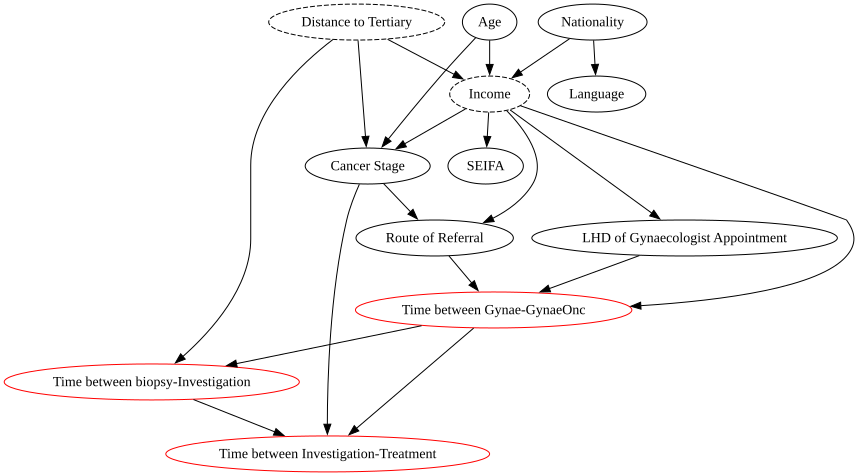

In [15]:
utils.draw_causal_graph(
    edge_list=[
        ("Age", "Income"), # possible nonlinearities
        ('Income', "SEIFA"),
        ('Nationality', 'Income'),
        ('Nationality', 'Language'),
        ('Income', "Route of Referral"),
        ('Income', 'LHD of Gynaecologist Appointment'),
        #('Route of Referral', "C"),
        ('Income', 'Cancer Stage'),
        ('Age', 'Cancer Stage'),
        #('Cancer Stage', "Time of Biopsy"),
        ('Income', "Time between Gynae-GynaeOnc"),
        ('Route of Referral', "Time between Gynae-GynaeOnc"),
        ('LHD of Gynaecologist Appointment','Time between Gynae-GynaeOnc'),
        ('Time between Gynae-GynaeOnc', "Time between Investigation-Treatment"),
        ('Time between Gynae-GynaeOnc', "Time between biopsy-Investigation"),
        ('Time between biopsy-Investigation', "Time between Investigation-Treatment"),
        ('Cancer Stage', "Time between Investigation-Treatment"),
        ('Cancer Stage', "Route of Referral"),
        ('Distance to Tertiary', "Income"),
        ('Distance to Tertiary', "Cancer Stage"),
        ('Distance to Tertiary', "Time between biopsy-Investigation")
        
    ],
    node_props={
        "Income": {'style': 'dashed'},
        "Time between Gynae-GynaeOnc": {"color": "red"},
        "Time between biopsy-Investigation": {"color": "red"},
        "Time between Investigation-Treatment": {"color": "red"},
        "Distance to Tertiary": {'style': 'dashed'},
    }
)

In [ ]:
x = 5